In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
df = pd.read_csv(r"C:\Users\Shashank\Downloads\Projects\Predictive_Maintenance_Intelligence\data\raw\ai4i2020.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [8]:
df.shape

(10000, 14)

In [9]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [10]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [12]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [13]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [14]:
 df.duplicated().sum()


np.int64(0)

In [15]:
# =====================================================
# STEP 17: TARGET VARIABLE ANALYSIS
# =====================================================

target = "Machine failure"

print("Target Distribution:")
print(df[target].value_counts())

print("\nTarget Percentage:")
print(
    df[target].value_counts(normalize=True) * 100
)

Target Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Target Percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


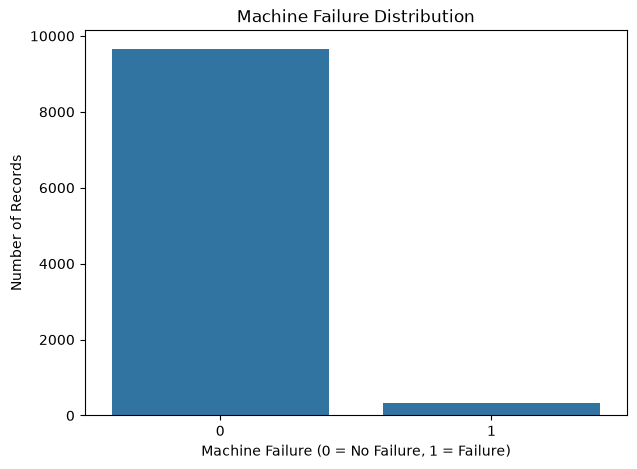

In [16]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Number of Records")

plt.show()

In [17]:
# =====================================================
# STEP 18: FAILURE MODE ANALYSIS
# =====================================================

failure_columns = [
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

failure_summary = pd.DataFrame({
    "Failure Type": failure_columns,
    "Failure Count": [
        df[column].sum()
        for column in failure_columns
    ]
})

failure_summary

,Failure Type,Failure Count
0,TWF,46
1,HDF,115
2,PWF,95
3,OSF,98
4,RNF,19


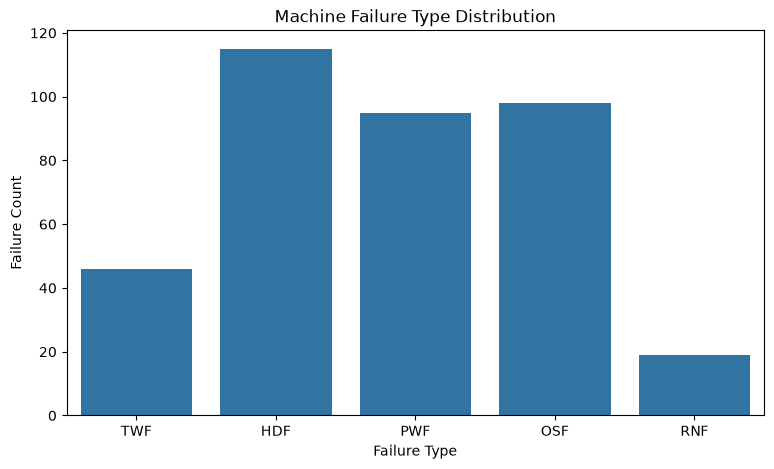

In [18]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=failure_summary,
    x="Failure Type",
    y="Failure Count"
)

plt.title("Machine Failure Type Distribution")
plt.xlabel("Failure Type")
plt.ylabel("Failure Count")

plt.show()

In [20]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [21]:
for col in df.columns:
    print(col, ":", df[col].nunique())

UDI : 10000
Product ID : 10000
Type : 3
Air temperature [K] : 93
Process temperature [K] : 82
Rotational speed [rpm] : 941
Torque [Nm] : 577
Tool wear [min] : 246
Machine failure : 2
TWF : 2
HDF : 2
PWF : 2
OSF : 2
RNF : 2


In [22]:
print(df["Type"].value_counts())
print("\nPercentage Distribution:")
print(df["Type"].value_counts(normalize=True) * 100)

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Percentage Distribution:
Type
L    60.00
M    29.97
H    10.03
Name: proportion, dtype: float64


In [23]:
# ==========================================
# PHASE 2: EXPLORATORY DATA ANALYSIS
# STEP 1: FEATURE SEPARATION
# ==========================================

# Identify numerical columns
numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_features = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['UDI', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Categorical Features:
['Product ID', 'Type']


In [24]:
# ==========================================
# STEP 2: FEATURE CLASSIFICATION
# ==========================================

# Identifier columns
identifier_features = [
    "UDI",
    "Product ID"
]

# Categorical features
categorical_features = [
    "Type"
]

# Sensor features
sensor_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Target variable
target_feature = "Machine failure"

# Failure indicators
failure_features = [
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

print("Identifier Features:", identifier_features)
print("Categorical Features:", categorical_features)
print("Sensor Features:", sensor_features)
print("Target Feature:", target_feature)
print("Failure Indicators:", failure_features)

Identifier Features: ['UDI', 'Product ID']
Categorical Features: ['Type']
Sensor Features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Target Feature: Machine failure
Failure Indicators: ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [25]:
# ==========================================
# STEP 3: SENSOR FEATURE SUMMARY
# ==========================================

sensor_summary = df[sensor_features].describe().T

sensor_summary

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0


In [26]:
# ==========================================
# STEP 4: CATEGORICAL FEATURE ANALYSIS
# ==========================================

for col in categorical_features:

    print(f"\nAnalysis of {col}")

    print(df[col].value_counts())

    print("\nPercentage Distribution:")

    print(
        df[col].value_counts(normalize=True) * 100
    )


Analysis of Type
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Percentage Distribution:
Type
L    60.00
M    29.97
H    10.03
Name: proportion, dtype: float64


In [27]:
# ==========================================
# STEP 5: TARGET VARIABLE ANALYSIS
# ==========================================

print("Machine Failure Distribution")

print(df[target_feature].value_counts())

print("\nPercentage Distribution")

print(
    df[target_feature].value_counts(normalize=True) * 100
)

Machine Failure Distribution
Machine failure
0    9661
1     339
Name: count, dtype: int64

Percentage Distribution
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


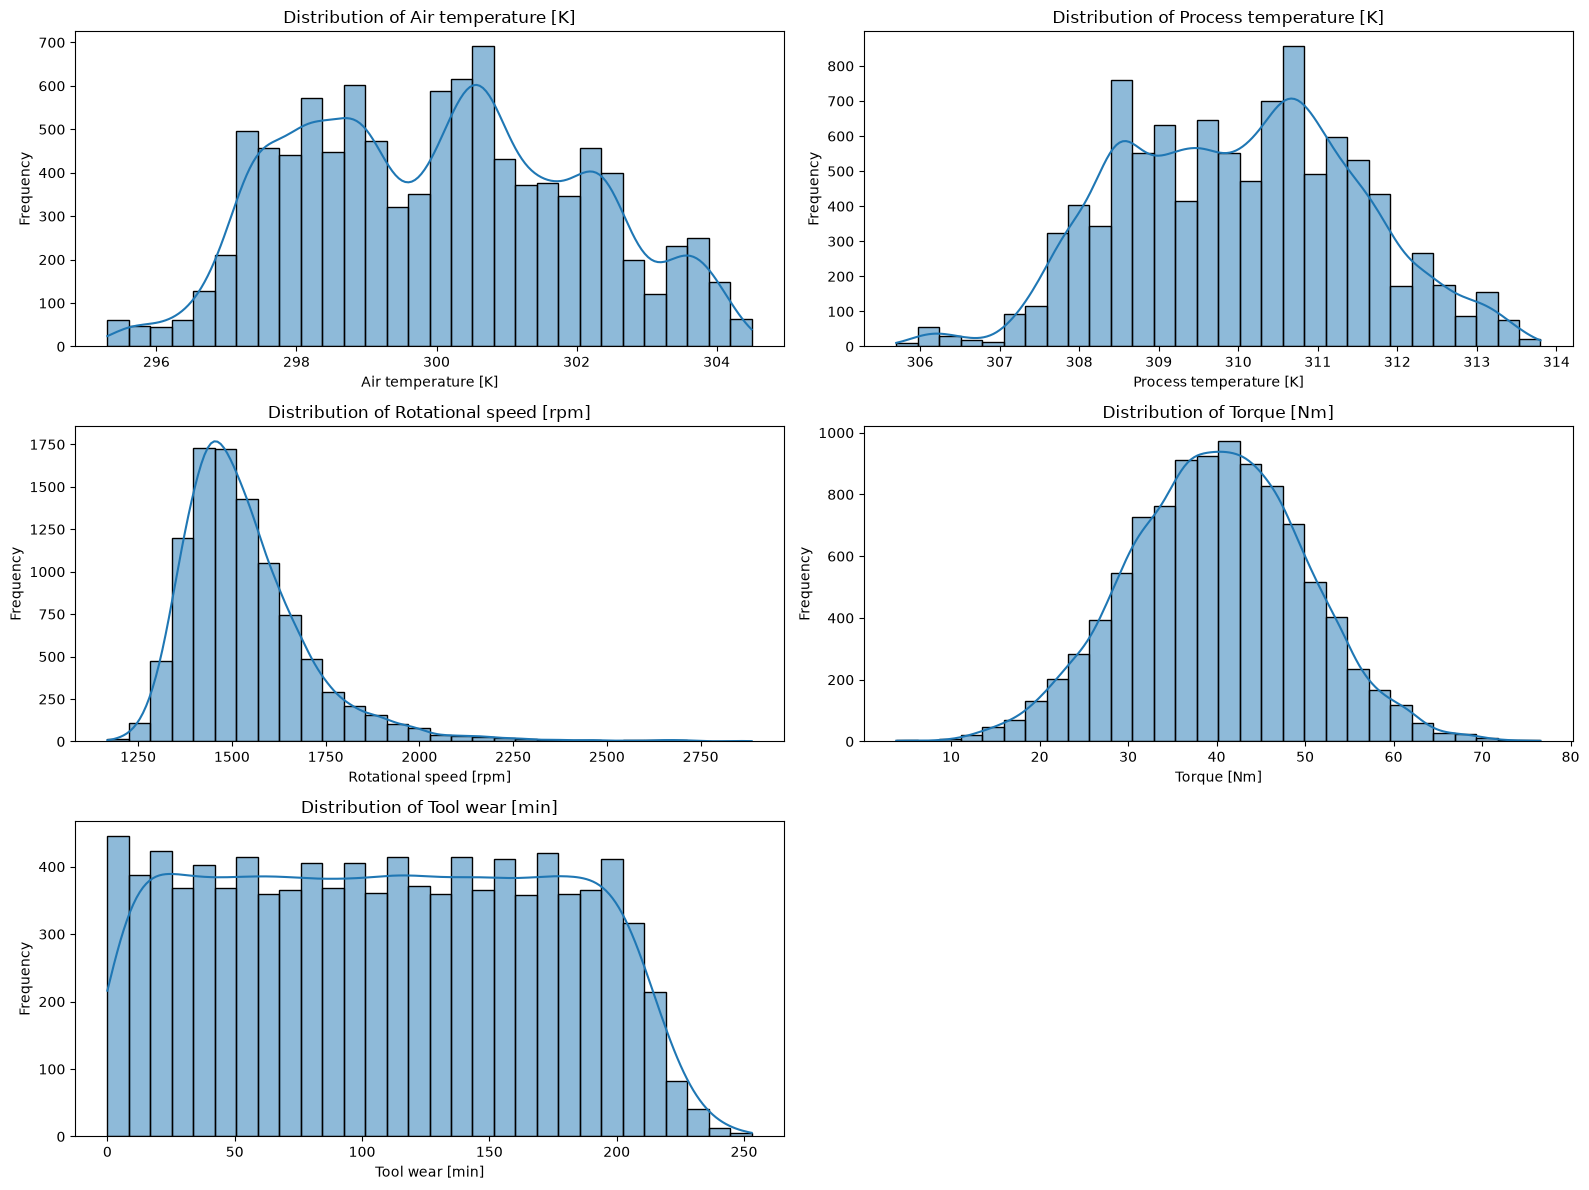

In [28]:
# ==========================================
# STEP 6: SENSOR DISTRIBUTION
# ==========================================

plt.figure(figsize=(16, 12))

for i, col in enumerate(sensor_features, 1):

    plt.subplot(3, 2, i)

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")

    plt.xlabel(col)

    plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

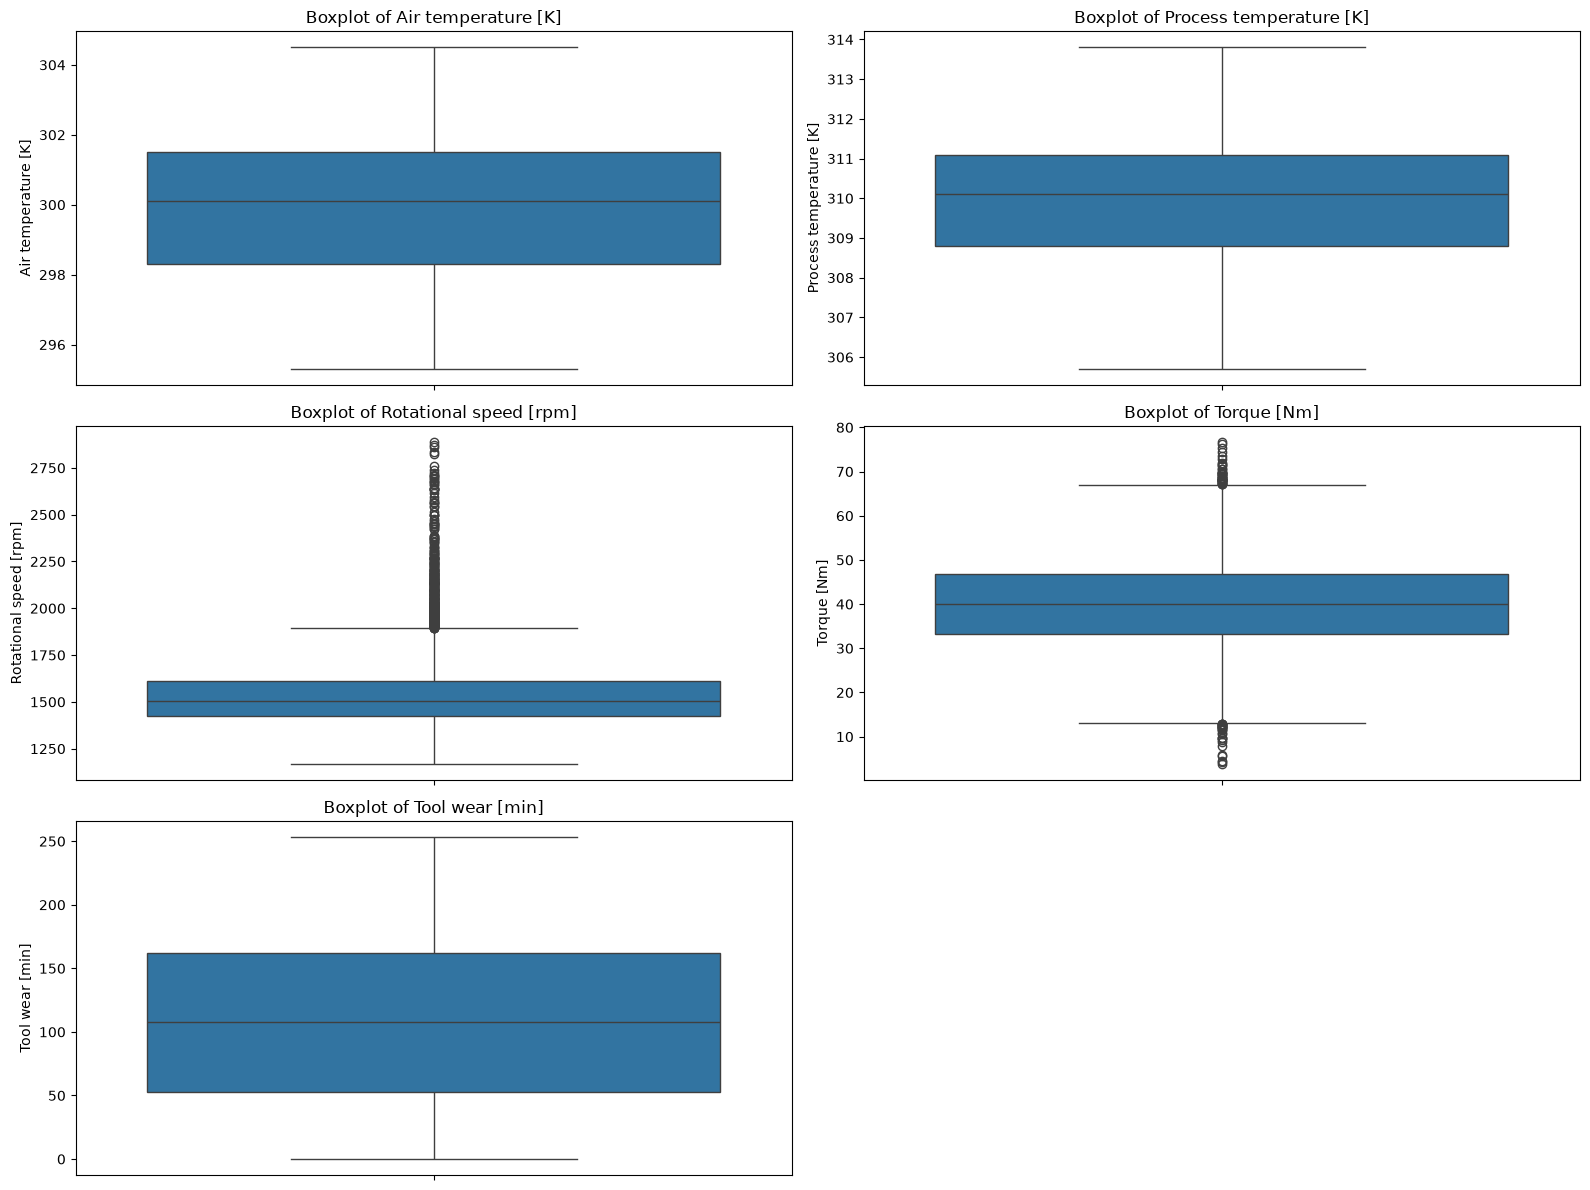

In [29]:
# =====================================================
# STEP 7.1: BOXPLOT ANALYSIS
# =====================================================

plt.figure(figsize=(16, 12))

for i, col in enumerate(sensor_features, 1):

    plt.subplot(3, 2, i)

    sns.boxplot(
        data=df,
        y=col
    )

    plt.title(f"Boxplot of {col}")
    plt.ylabel(col)

plt.tight_layout()
plt.show()

In [30]:
# =====================================================
# STEP 7.2: IQR OUTLIER DETECTION
# =====================================================

outlier_results = []

for col in sensor_features:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": (
            len(outliers) / len(df)
        ) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Air temperature [K],298.3,301.5,3.2,293.50,306.30,0,0.00
1,Process temperature [K],308.8,311.1,2.3,305.35,314.55,0,0.00
2,Rotational speed [rpm],1423.0,1612.0,189.0,1139.50,1895.50,418,4.18
3,Torque [Nm],33.2,46.8,13.6,12.80,67.20,69,0.69
4,Tool wear [min],53.0,162.0,109.0,-110.50,325.50,0,0.00


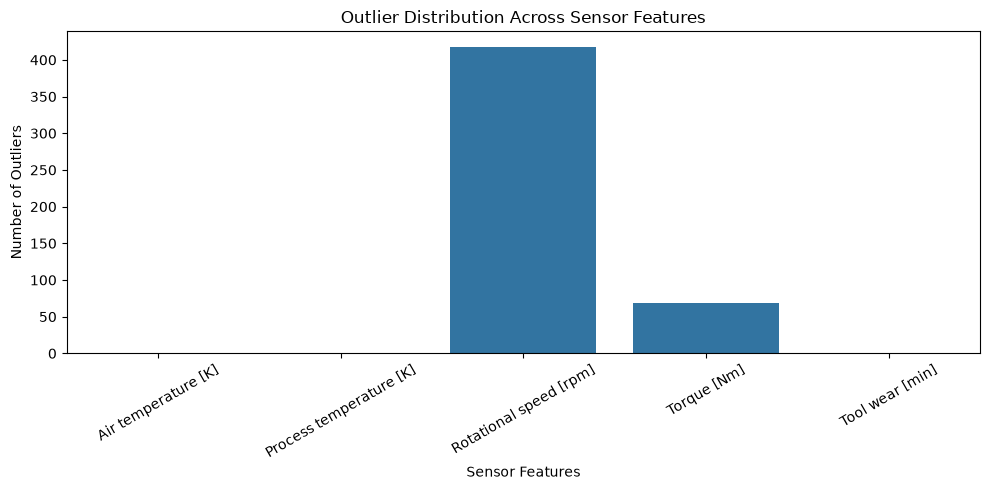

In [31]:
# =====================================================
# STEP 7.3: OUTLIER COUNT VISUALIZATION
# =====================================================

plt.figure(figsize=(10, 5))

sns.barplot(
    data=outlier_df,
    x="Feature",
    y="Outlier Count"
)

plt.title("Outlier Distribution Across Sensor Features")

plt.xlabel("Sensor Features")
plt.ylabel("Number of Outliers")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [32]:
# =====================================================
# STEP 7.4: EXTREME VALUE ANALYSIS
# =====================================================

for col in sensor_features:

    print("\nFeature:", col)

    print("Minimum:", df[col].min())

    print("Maximum:", df[col].max())

    print("Median:", df[col].median())

    print("-" * 40)


Feature: Air temperature [K]
Minimum: 295.3
Maximum: 304.5
Median: 300.1
----------------------------------------

Feature: Process temperature [K]
Minimum: 305.7
Maximum: 313.8
Median: 310.1
----------------------------------------

Feature: Rotational speed [rpm]
Minimum: 1168
Maximum: 2886
Median: 1503.0
----------------------------------------

Feature: Torque [Nm]
Minimum: 3.8
Maximum: 76.6
Median: 40.1
----------------------------------------

Feature: Tool wear [min]
Minimum: 0
Maximum: 253
Median: 108.0
----------------------------------------


In [35]:
# =====================================================
# STEP 8.1: CORRELATION DATA PREPARATION
# =====================================================

correlation_features = sensor_features + [
    "Machine failure"
]

correlation_df = df[correlation_features]

print("Correlation Dataset Shape:", correlation_df.shape)

correlation_df.head()

Correlation Dataset Shape: (10000, 6)


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,298.1,308.6,1551,42.8,0,0
1,298.2,308.7,1408,46.3,3,0
2,298.1,308.5,1498,49.4,5,0
3,298.2,308.6,1433,39.5,7,0
4,298.2,308.7,1408,40.0,9,0


In [37]:
# =====================================================
# STEP 8.2: CORRELATION MATRIX
# =====================================================

correlation_matrix = correlation_df.corr(
    method="pearson"
)

correlation_matrix

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.000000,0.876107,0.022670,-0.013778,0.013853,0.082556
Process temperature [K],0.876107,1.000000,0.019277,-0.014061,0.013488,0.035946
Rotational speed [rpm],0.022670,0.019277,1.000000,-0.875027,0.000223,-0.044188
Torque [Nm],-0.013778,-0.014061,-0.875027,1.000000,-0.003093,0.191321
Tool wear [min],0.013853,0.013488,0.000223,-0.003093,1.000000,0.105448
Machine failure,0.082556,0.035946,-0.044188,0.191321,0.105448,1.000000


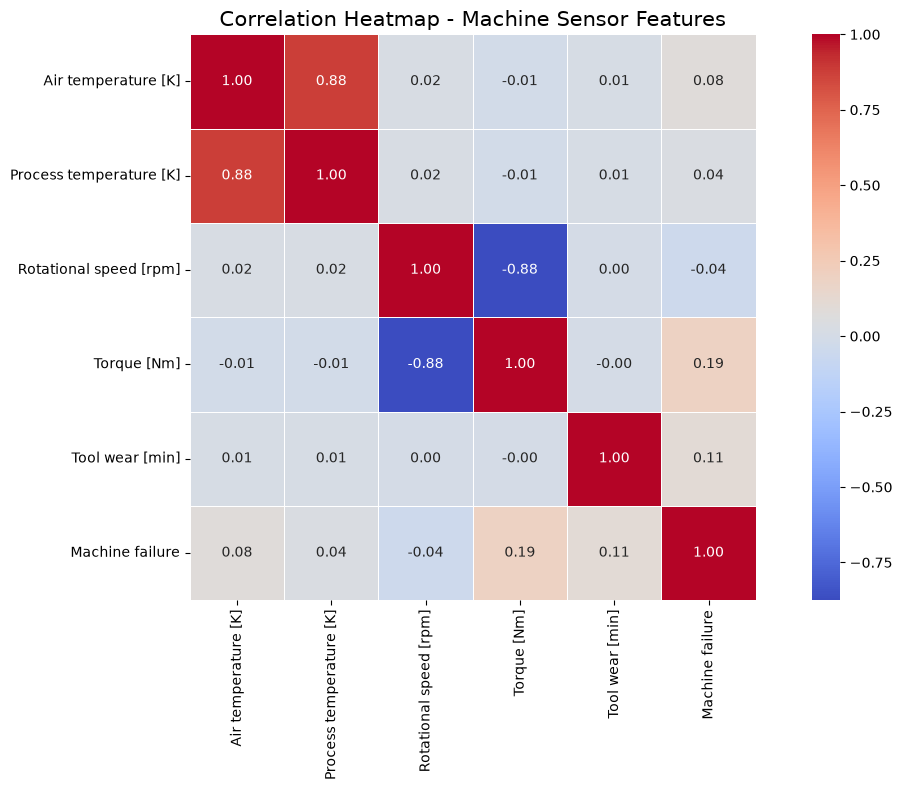

In [38]:
# =====================================================
# STEP 8.3: CORRELATION HEATMAP
# =====================================================

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    square=True
)

plt.title(
    "Correlation Heatmap - Machine Sensor Features",
    fontsize=15
)

plt.tight_layout()

plt.show()

In [39]:
# =====================================================
# STEP 8.4: STRONGEST FEATURE CORRELATIONS
# =====================================================

corr_pairs = (
    correlation_matrix
    .where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

corr_pairs["Absolute Correlation"] = (
    corr_pairs["Correlation"].abs()
)

corr_pairs = corr_pairs.sort_values(
    by="Absolute Correlation",
    ascending=False
)

corr_pairs

,Feature 1,Feature 2,Correlation,Absolute Correlation
1,Air temperature [K],Process temperature [K],0.876107,0.876107
15,Rotational speed [rpm],Torque [Nm],-0.875027,0.875027
23,Torque [Nm],Machine failure,0.191321,0.191321
29,Tool wear [min],Machine failure,0.105448,0.105448
5,Air temperature [K],Machine failure,0.082556,0.082556
17,Rotational speed [rpm],Machine failure,-0.044188,0.044188
11,Process temperature [K],Machine failure,0.035946,0.035946
2,Air temperature [K],Rotational speed [rpm],0.022670,0.022670
8,Process temperature [K],Rotational speed [rpm],0.019277,0.019277
9,Process temperature [K],Torque [Nm],-0.014061,0.014061


In [40]:
# =====================================================
# STEP 9.1: FAILURE VS NON-FAILURE ANALYSIS
# =====================================================

failure_comparison = df.groupby(
    "Machine failure"
)[sensor_features].mean().T

failure_comparison.columns = [
    "No Failure",
    "Failure"
]

failure_comparison["Difference"] = (
    failure_comparison["Failure"] -
    failure_comparison["No Failure"]
)

failure_comparison

,No Failure,Failure,Difference
Air temperature [K],299.973999,300.886431,0.912432
Process temperature [K],309.995570,310.290265,0.294696
Rotational speed [rpm],1540.260014,1496.486726,-43.773289
Torque [Nm],39.629655,50.168142,10.538486
Tool wear [min],106.693717,143.781711,37.087994


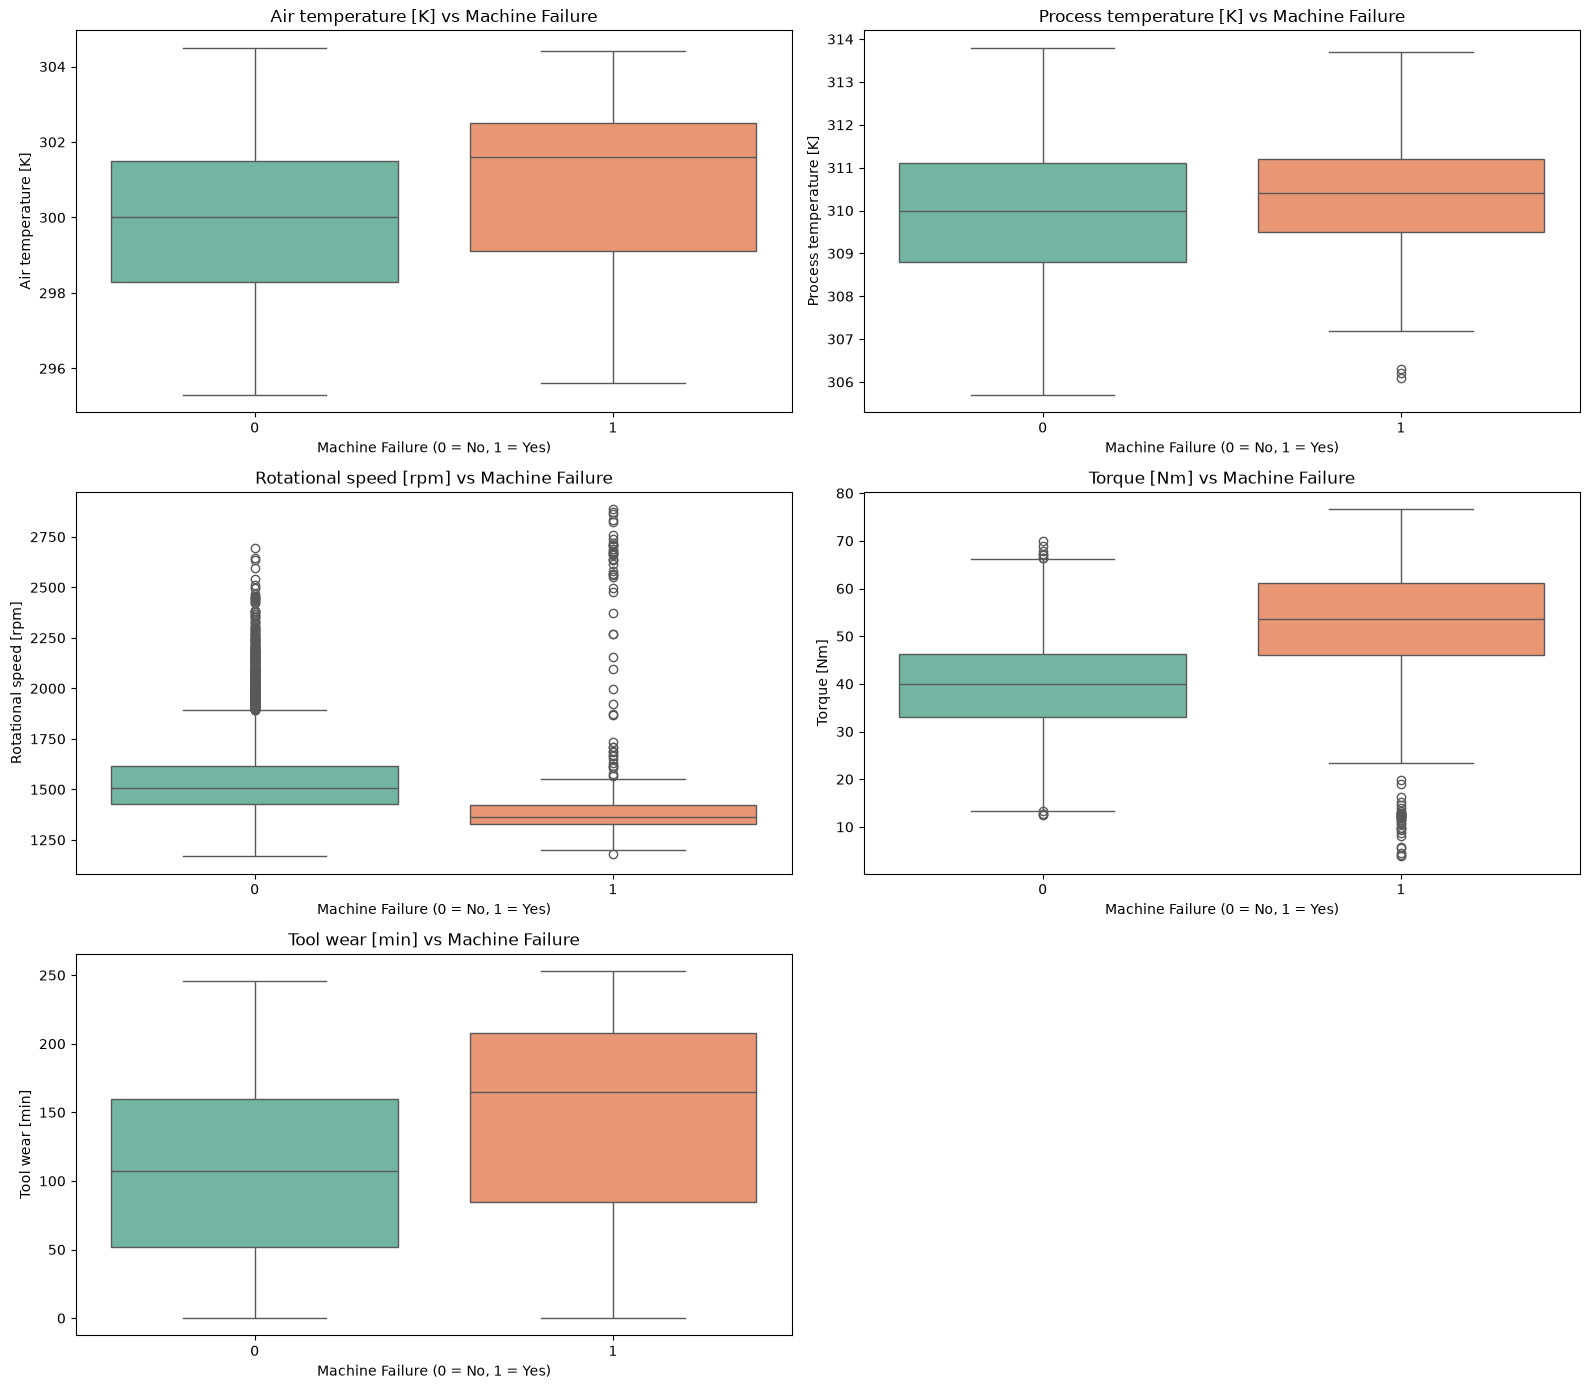

In [41]:
# =====================================================
# STEP 9.2: SENSOR COMPARISON BOXPLOTS
# =====================================================

plt.figure(figsize=(16, 14))

for i, col in enumerate(sensor_features, 1):

    plt.subplot(3, 2, i)

    sns.boxplot(
        data=df,
        x="Machine failure",
        y=col,
        hue="Machine failure",
        palette="Set2",
        legend=False
    )

    plt.title(f"{col} vs Machine Failure")

    plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
    plt.ylabel(col)

plt.tight_layout()
plt.show()

In [42]:
# =====================================================
# STEP 9.3: FAILURE RATE BY PRODUCT TYPE
# =====================================================

type_failure = df.groupby("Type").agg(
    Total_Records=("Machine failure", "count"),
    Total_Failures=("Machine failure", "sum"),
    Failure_Rate=("Machine failure", "mean")
)

type_failure["Failure_Rate"] *= 100

type_failure

,Total_Records,Total_Failures,Failure_Rate
Type,,,
H,1003,21,2.093719
L,6000,235,3.916667
M,2997,83,2.769436


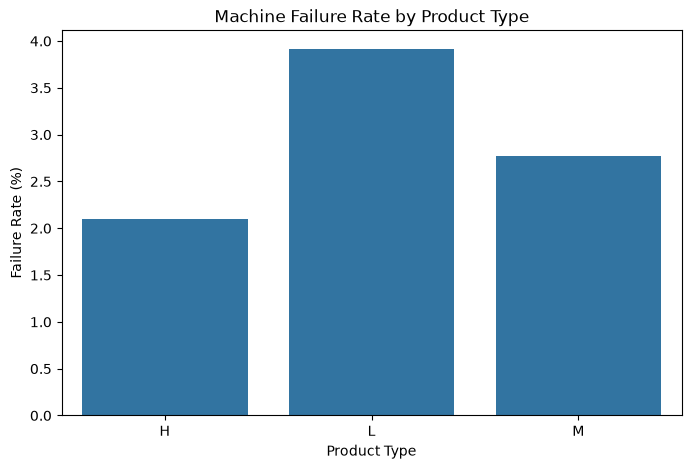

In [43]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=type_failure.reset_index(),
    x="Type",
    y="Failure_Rate"
)

plt.title("Machine Failure Rate by Product Type")

plt.xlabel("Product Type")
plt.ylabel("Failure Rate (%)")

plt.show()

In [44]:
# =====================================================
# STEP 10.1: FAILURE TYPE COUNT ANALYSIS
# =====================================================

failure_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]

failure_counts = df[failure_columns].sum()

failure_summary = pd.DataFrame({
    "Failure Type": failure_counts.index,
    "Failure Count": failure_counts.values
})

failure_summary

,Failure Type,Failure Count
0,TWF,46
1,HDF,115
2,PWF,95
3,OSF,98
4,RNF,19


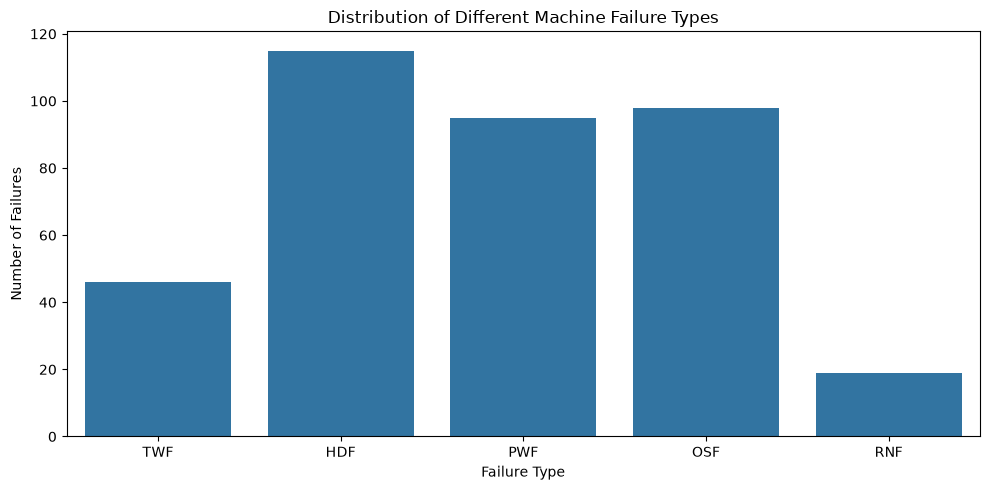

In [45]:
# =====================================================
# STEP 10.2: FAILURE TYPE DISTRIBUTION
# =====================================================

plt.figure(figsize=(10, 5))

sns.barplot(
    data=failure_summary,
    x="Failure Type",
    y="Failure Count"
)

plt.title("Distribution of Different Machine Failure Types")
plt.xlabel("Failure Type")
plt.ylabel("Number of Failures")

plt.tight_layout()
plt.show()

In [46]:
# =====================================================
# STEP 10.3: FAILURE TYPE PERCENTAGES
# =====================================================

failure_summary["Failure Percentage"] = (
    failure_summary["Failure Count"] / len(df)
) * 100

failure_summary

,Failure Type,Failure Count,Failure Percentage
0,TWF,46,0.46
1,HDF,115,1.15
2,PWF,95,0.95
3,OSF,98,0.98
4,RNF,19,0.19


In [47]:
# =====================================================
# STEP 10.4: FAILURE MODE SENSOR ANALYSIS
# =====================================================

for failure in failure_columns:

    print("\nFailure Type:", failure)

    comparison = df.groupby(failure)[sensor_features].mean().T

    comparison.columns = ["No Failure", "Failure"]

    print(comparison)


Failure Type: TWF
                          No Failure      Failure
Air temperature [K]       300.003576   300.297826
Process temperature [K]   310.004822   310.165217
Rotational speed [rpm]   1538.649488  1566.173913
Torque [Nm]                39.996845    37.836957
Tool wear [min]           107.449970   216.369565

Failure Type: HDF
                          No Failure      Failure
Air temperature [K]       299.975195   302.560870
Process temperature [K]   309.996449   310.788696
Rotational speed [rpm]   1541.120486  1337.260870
Torque [Nm]                39.833576    53.166957
Tool wear [min]           107.959838   107.191304

Failure Type: PWF
                          No Failure      Failure
Air temperature [K]       300.004250   300.075789
Process temperature [K]   310.006047   309.954737
Rotational speed [rpm]   1536.616254  1763.968421
Torque [Nm]                39.905119    48.514737
Tool wear [min]           108.009187   101.884211

Failure Type: OSF
                        

In [48]:
# ==============================================
# STEP 11.1: FAILURE MODE FREQUENCY
# ==============================================

failure_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]

failure_counts = df[failure_columns].sum()

failure_frequency = pd.DataFrame({
    "Failure Type": failure_counts.index,
    "Count": failure_counts.values
})

failure_frequency["Percentage"] = (
    failure_frequency["Count"] / len(df)
) * 100

failure_frequency

,Failure Type,Count,Percentage
0,TWF,46,0.46
1,HDF,115,1.15
2,PWF,95,0.95
3,OSF,98,0.98
4,RNF,19,0.19


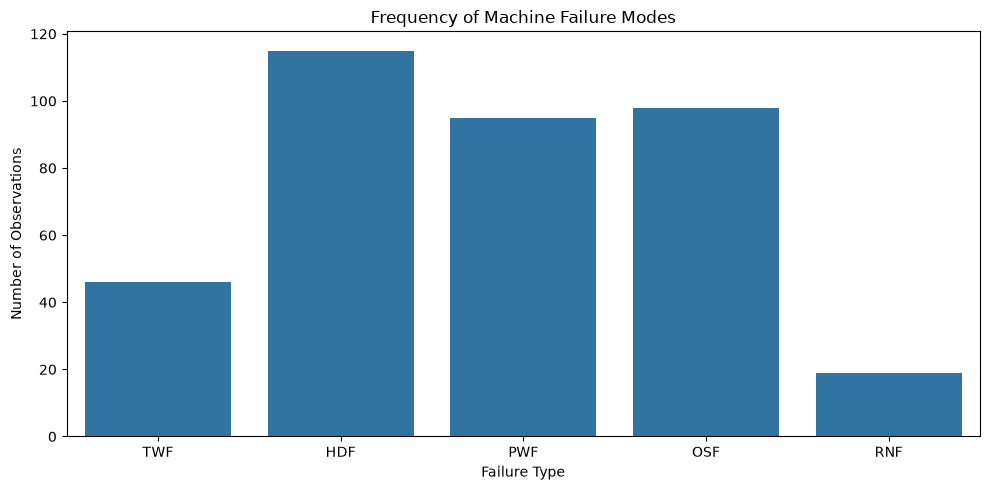

In [49]:
# ==============================================
# STEP 11.2: FAILURE FREQUENCY CHART
# ==============================================

plt.figure(figsize=(10, 5))

sns.barplot(
    data=failure_frequency,
    x="Failure Type",
    y="Count"
)

plt.title("Frequency of Machine Failure Modes")
plt.xlabel("Failure Type")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

In [50]:
# ==============================================
# STEP 11.3: FAILURE MODE OVERLAP
# ==============================================

df["Total Failure Modes"] = df[
    failure_columns
].sum(axis=1)

print("Failure Mode Combinations:")

print(
    df["Total Failure Modes"].value_counts().sort_index()
)

Failure Mode Combinations:
Total Failure Modes
0    9652
1     324
2      23
3       1
Name: count, dtype: int64


In [51]:
# ==============================================
# STEP 11.4: FAILURE INDICATOR CONSISTENCY
# ==============================================

mode_present = df[failure_columns].any(axis=1)

print(
    "Machine failures:",
    df["Machine failure"].sum()
)

print(
    "Records with at least one failure mode:",
    mode_present.sum()
)

print(
    "Machine failures without listed failure modes:",
    (
        (df["Machine failure"] == 1) &
        (~mode_present)
    ).sum()
)

Machine failures: 339
Records with at least one failure mode: 348
Machine failures without listed failure modes: 9
